# 9. Diels-Alder Reaction: Intrinsic Reaction Coordinates

One of the most **useful** activities in computational chemistry is examining **reaction energy barriers**. If we can compare the energy of a **transition state** as we change structure, we can learn the reasons for these **kinetic** effects and make predictions. Calculating transition state structure and energy is **challenging**. Partially formed bonds and separated charges require **higher levels** of theory to accurately describe and so the computation **cost** rises rapidly. The T.S. itself may not be easy to find, especially when there are high degrees of freedom (lots of ways to arrange the structure).

So let us start with a common example, the **Diels-Alder reaction**. This pericyclic addition reaction is a good candidate for these calculations because of its **organized** transition state (fewer degrees of freedom) and lack of charge separation. We will perform a reaction coordinate **scan** in hopes of **finding** a structure that is **close** to the transition state. We will then perform a Hessian calculation to confirm the presence of an **imaginary vibration**. If we have an imaginary vibration, we have a direction towards the transition state. We will then perform a **saddle point optimization** to find the transition state. Finally, we will perform an **intrinsic reaction coordinate** calculation to calculate the path from the transition state to the ground-state reactants on either side.

Every *GAMESS* job on this page is run from this notebook with *Python*, and every number we need from a log or `.dat` file is read by *Python* instead of by eye. *MacMolPlt* is still the tool for building the molecule and for looking at structures, vibrations and the final movie.

:::{note} Mac users: after a restart
macOS resets the shared-memory limits every time you restart. If a *GAMESS* job stops with a fatal error and the `.log` file shows `shmget returned an error`, set the limits again (see [Raise shared-memory limits](#shared-memory-limits) in [](1D-CompileInstruction2024.md)).
:::

### Settings

Run this cell first. It loads the book's helper module, `gamess_tools.py`, which finds *GAMESS* using the location you set in `gamess_settings.py` on the [setup page](1_Setup.ipynb). All the jobs write their `.log` and `.dat` files into the `runs/ch8/` folder next to this notebook. That is the folder to look in when you open a result in *MacMolPlt*.

Every job below is run with `rerun=False`: if a finished log file is already in `runs/ch8/`, it is used again instead of running the job a second time. Delete the log file (or change to `rerun=True`) to run a job again.

In [1]:
# ===== SETTINGS =========================================================
# Your GAMESS location is set ONCE, in gamess_settings.py (next to this
# notebook). Edit that file, save it, and restart the kernel.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gamess_tools as gt

INPUTS = Path("inputs/ch8") # input files for this chapter
RUNS = Path("runs/ch8")     # where log files and new input files are written
RUNS.mkdir(parents=True, exist_ok=True)
gt.RUN_FOLDER = RUNS        # run_gamess() writes its files here

HARTREE_TO_KJMOL = 2625.5   # 1 hartree = 2625.5 kJ/mol
# ========================================================================

## Starting the Journey to the T.S.

The easiest way to find the T.S. for a cycloaddition reaction is to start with a **symmetrical** system and run a **scan** of distances between the atoms that form the new bonds. In a symmetrical system, the two bond lengths should be identical in the T.S. The reaction that we will model is presented in {numref}`fig8_1`.

```{figure} images/ch8/Diels_1.png
---
width: 450px
name: fig8_1
---
*A typical Diels-Alder cycloaddition reaction.*
```

The easiest approach is to model the **product** and then calculate minimized structures as we force the two new bonds **apart**. Hopefully, we will encounter the transition state along that coordinate.

First we will **build** the product, cyclohexene, using *MacMolPlt* and then create an **input file** for a structure optimization. We will use the 6-31G<sup>\*</sup> basis set for the real work (after a first look with the smaller 3-21G<sup>\*</sup>). Our calculations should still finish in minutes – I hope.

### Building Cyclohexene

Using the `Builder` tool panel in *wxMacMolPlt*, choose carbon with a coordination number of 3. Add the two carbon atoms of the alkene group. Then increase the coordination number to 4 and add an *sp<sup>3</sup>* carbon to each end of the alkene. Then add one more *sp<sup>3</sup>* carbon to each of the current *sp<sup>3</sup>* carbon atoms. We now have six carbon atoms in total. Now grab each terminal *sp<sup>3</sup>* carbon and move them in space to try to connect them together without breaking any bonds. Fiddle with it a bit and you’ll get the knack. In the end we will have a structure like that shown in {numref}`fig8_2`.

```{figure} images/ch8/Diels_2.png
---
width: 450px
name: fig8_2
---
*The initial structure for cyclohexene in MacMolPlt.*
```

**Export** an input file from `Subwindow` &rarr; `Input Builder`. We choose a `Runtype: Optimization` with the `3-21G` basis set with `1 D Heavy Atom Polarization Function` (3-21G<sup>\*</sup>). We set `Coord. Type: Z-Matrix` and `# of Z-Matrix Variables` to `42` (3 × 16 atoms – 6).

The input file, `inputs/ch8/Cyclohexene.inp`, comes with the book. Here it is.

In [2]:
print((INPUTS / "Cyclohexene.inp").read_text())

!   File created by MacMolPlt 7.7.2
 $CONTRL SCFTYP=RHF RUNTYP=OPTIMIZE MAXIT=30 MULT=1 COORD=ZMT NZVAR=42 NOSYM=1 
    MOLPLT=.TRUE. $END
 $SYSTEM TIMLIM=525600 MEMORY=1000000 $END
 $BASIS GBASIS=N21 NGAUSS=3 NDFUNC=1 $END
 $SCF DIRSCF=.TRUE. $END
 $STATPT OPTTOL=0.0001 NSTEP=50 $END
 $DATA 
Cyclohexene
C1
C
C   1    1.54000
C   2    1.54000  1 120.0000
C   1    1.54000  2 120.0000  3   0.0000
C   4    1.41037  1  89.6402  2  47.3676
C   3    1.42617  2  96.3800  5 -23.8081
H   1    1.14000  4 120.0000  2 180.0000
H   2    1.14000  1 120.0000  3 180.0000
H   3    1.14000  6 112.6374  2 117.7914
H   3    1.14000  9 110.4255  6 -126.1402
H   4    1.14000  5 114.1752  1 116.4929
H   4    1.14000  11 111.0397  5 -129.4079
H   5    1.14000  4 104.3204  6 -122.5757
H   5    1.14000  13 108.4843  4 111.1625
H   6    1.14000  3 107.6066  5 -121.0604
H   6    1.14000  15 109.0496  3 116.6663
 $END
 $ZMAT IZMAT(1)=1,2,1, 1,3,2, 2,3,2,1, 1,4,1, 2,4,1,2, 3,4,1,2,3, 1,5,4, 
    2,5,4,1, 3,5,4,1,2,

We **submit** the file to *GAMESS* from *Python*. It takes a few seconds.

In [3]:
cyclohexene_log = gt.run_gamess(INPUTS / "Cyclohexene.inp", rerun=False)
step, energy, gmax, rms = gt.optimization_steps(cyclohexene_log)[-1]
print(f"{step} steps, final energy {energy:.10f} hartree, largest gradient {gmax:.7f}")

Cyclohexene: using existing Cyclohexene.log (rerun=True to run again)
17 steps, final energy -231.7203739787 hartree, largest gradient 0.0000843


After the **optimization**, a structure was found with a minimum energy. It may not be the global minimum but it is the conformer that will relate to the path **toward** the transition state. Observe the changes. One large change is the distance between atoms 1 and 2 (the C=C alkene bond). In the **initial** structure it was created with the length of a single bond (1.54&nbsp;Å) but it **settled down** to the length of a double bond (about 1.32&nbsp;Å).

Because we gave *GAMESS* a *Z-matrix* (`NZVAR=42`), the log file ends with a table of the **internal coordinates** of the final structure. The function `gt.internal_coordinates()` reads it for us. We **see** that the bonds that we want to stretch as we move toward the transition state are C5–C4 and C6–C3. These two **bond lengths** are the 7<sup>th</sup> and 10<sup>th</sup> `$ZMAT` coordinates, and they are marked with arrows below, together with the C1=C2 bond.

In [4]:
table = pd.DataFrame(gt.internal_coordinates(cyclohexene_log), columns=["type", "atoms", "value"])
table.index += 1                                   # number the rows from 1, like GAMESS
watch = [(2, 1), (5, 4), (6, 3)]
table["note"] = ["<--" if atoms in watch else "" for atoms in table["atoms"]]
print(table.to_string())

       type           atoms       value note
1   STRETCH          (2, 1)    1.317660  <--
2   STRETCH          (3, 2)    1.513365     
3      BEND       (3, 2, 1)  118.640777     
4   STRETCH          (4, 1)    1.513406     
5      BEND       (4, 1, 2)  118.640461     
6   TORSION    (4, 1, 2, 3)    0.013361     
7   STRETCH          (5, 4)    1.554360  <--
8      BEND       (5, 4, 1)  110.086396     
9   TORSION    (5, 4, 1, 2)   47.857684     
10  STRETCH          (6, 3)    1.554210  <--
11     BEND       (6, 3, 2)  110.066332     
12  TORSION    (6, 3, 2, 5)  -23.164150     
13  STRETCH          (7, 1)    1.073220     
14     BEND       (7, 1, 4)  119.342185     
15  TORSION    (7, 1, 4, 2) -179.828914     
16  STRETCH          (8, 2)    1.073208     
17     BEND       (8, 2, 1)  122.017506     
18  TORSION    (8, 2, 1, 3) -179.857492     
19  STRETCH          (9, 3)    1.083052     
20     BEND       (9, 3, 6)  109.614121     
21  TORSION    (9, 3, 6, 2)  122.655905     
22  STRETC

I will **open** the log file (`runs/ch8/Cyclohexene.log`) with *MacMolPlt* and choose to **view** the atom labels. I chose to **display** the atom numbers by selecting `View` &rarr; `Atom Labels` &rarr; `Atom Number`. We can now clearly **see** that the bond lengths between carbons 4,5 and 3,6 are going to define the reaction coordinate. See {numref}`fig8_3`.

```{figure} images/ch8/Diels_3.png
---
width: 450px
name: fig8_3
---
*Optimized structure of cyclohexene*
```

We did not use **symmetry** in the above calculation. The optimization **found** the symmetrical boat conformation of cyclohexene because we started very close to it with our initial structure. The more stable half-chair **conformation** could easily have been the result. Also, in my reading, I have learned that the boat conformation is a **shallow energy well** in a wide energy “plateau” between the two possible half-chair conformations {cite:p}`Shishkin2011`. This means that it has a high entropy and could easily swing off-track when we are trying to scan bond distances. However, *GAMESS* will maintain symmetry when we request it and the boat conformation is *C<sub>s</sub>* and the half-chair is *C<sub>2</sub>*. So we might be able to keep things **in the groove** that way. Be prepared to tack if the wind changes.

As an exercise, let us **construct** the boat and half-chair versions of cyclohexene and compare their energies. We will use the symmetry builder function of *MacMolPlt* to build a molecule that fits the given symmetry exactly and then **enforce** that symmetry throughout the calculation.

### Building *C<sub>s</sub>* Cyclohexene

Open *MacMolPlt* and start a new file. Select `View` &rarr; `Show Axis` to display the three *xyz* axes. We must **keep track** of the axes when building with symmetry. The *C<sub>s</sub>* cyclohexene will have a *&sigma;<sub>xy</sub>* plane so we will want the three unique atoms above or below that plane so they can be **reflected** to the other side. However, *MacMolPlt* will place the first three atoms that you drop in into the *xy* plane. We will solve this by adding a single atom and then dragging it above the plane. Follow along and all will become clear.

Now let us **set up** the symmetry build. Click on `Builder` &rarr; `Edit with Symmetry`. Then we must **define** the symmetry we are using. Click on `Molecule` &rarr; `Set Point Group` &rarr; `Point Group` &rarr; `Cs`. We are now ready to add the first carbon.

Click on `Builder` &rarr; `Show Build Tools` and choose Carbon with a coordination number of 3 (this would be a *sp<sup>2</sup>* carbon). Click in the *MacMolPlt* window to place the atom. Now rotate the view in the window so that the *xy* plane becomes horizontal and the *z*-axis is vertical. Drag the carbon atom upwards and observe how its **reflection** appears on the other side of the *xy* plane. Drag it until you get a double bond between the atom and its doppelganger. Now go back to the `Build Tools` and choose carbon with a coordination number of 4 (this is *sp<sup>3</sup>*). Add a new carbon atom to one of the bonds and then extend the chain one more carbon. You will have three atoms and three reflected atoms placed. Drag the final carbon toward its mirror counterpart until *MacMolPlt* assigns a bond. Return to the `Build Tools` and choose Hydrogen. **Populate** all the remaining bonds with hydrogen atoms. We now have a starting structure.

Now we need to center the molecule in the symmetry system. *MacMolPlt* can make all the right decisions for us. Click on `Molecule` &rarr; `Set Coordinates to Principal Orientation` and the molecule will be centered on the *xyz* coordinate system. **Save your work**. The image in the *MacMolPlt* window might look like {numref}`fig8_4`.

```{figure} images/ch8/Diels_4.png
---
width: 500px
name: fig8_4
---
*Initial build of* C<sub>s</sub> *cyclohexene*
```

### Optimizing *C<sub>s</sub>* Cyclohexene

We know that *C<sub>s</sub>* cyclohexene is not the lowest energy conformer. But by **enforcing** the *C<sub>s</sub>* symmetry we can hold it in this conformation while it minimizes. Open `Subwindow` &rarr; `Input Builder` and set up an optimization at the 6-31G<sup>\*</sup> level. I initially created a *GAMESS* input file with *Z-matrix* coordinates but the calculation immediately failed. The nature of the *Z-matrix* often results in tiny **rounding errors** in the coordinate values **combining** to a slightly bigger error by the time the positioning has worked its way **along** all the internal coordinates. This error was obviously enough to place an atom or two outside of the **tolerance** for the symmetry calculation. We should use `Unique Coordinates` for symmetry calculations. The input file, `inputs/ch8/Cyclohexene_Cs_cart.inp`, is printed below. Only the eight symmetry-unique atoms are listed; *GAMESS* makes the other eight by reflection.

In [5]:
print((INPUTS / "Cyclohexene_Cs_cart.inp").read_text())

!   File created by MacMolPlt 7.7.2
 $CONTRL SCFTYP=RHF RUNTYP=OPTIMIZE MAXIT=30 MULT=1 COORD=UNIQUE NZVAR=42 
    MOLPLT=.TRUE. $END
 $SYSTEM TIMLIM=525600 MEMORY=1000000 $END
 $BASIS GBASIS=N31 NGAUSS=6 NDFUNC=1 $END
 $SCF DIRSCF=.TRUE. $END
 $STATPT OPTTOL=0.0001 NSTEP=30 $END
 $DATA 
Title
CS

C     6.0    -1.35474    -0.12747    -0.65064
C     6.0    -0.07172     0.23663    -1.42064
C     6.0     1.42646    -0.10916    -0.75855
H     1.0    -2.30450    -0.39699    -1.22064
H     1.0     1.75283    -1.13977    -1.12040
H     1.0    -0.12286    -0.30664    -2.42156
H     1.0     2.17392     0.67089    -1.12244
H     1.0    -0.10252     1.36058    -1.60873
 $END
 $ZMAT IZMAT(1)=1,2,1, 1,3,1, 2,3,1,2, 1,4,2, 2,4,2,1, 3,4,2,1,3, 1,5,3, 
    2,5,3,1, 3,5,3,1,4, 1,6,5, 2,6,5,3, 3,6,5,3,1, 1,7,1, 2,7,1,2, 3,7,1,2,3, 
    1,8,2, 2,8,2,1, 3,8,2,1,4, 1,9,5, 2,9,5,6, 3,9,5,6,3, 1,10,6, 2,10,6,5, 
    3,10,6,5,9, 1,11,3, 2,11,3,1, 3,11,3,1,5, 1,12,4, 2,12,4,2, 3,12,4,2,6, 
    1,13,5, 2,13,5,9

In [6]:
cs_log = gt.run_gamess(INPUTS / "Cyclohexene_Cs_cart.inp", rerun=False)

Cyclohexene_Cs_cart: using existing Cyclohexene_Cs_cart.log (rerun=True to run again)


This calculation completed **normally**. After it finished we find this block of text for the final results. The last `NSERCH` entry reveals that the calculation has reached a stationary point and finished. The energy is reported along with the symmetry unique *xyz* Cartesian coordinates, the full set of coordinates and the **internal coordinates** that were listed in the `IZMAT(1)` matrix. `gt.excerpt()` prints that part of the log file with its line numbers.

In [7]:
gt.excerpt(cs_log, "EQUILIBRIUM GEOMETRY LOCATED", before=3, after=31)

 7786   NSERCH:  13  E=     -233.0092034708  GRAD. MAX=  0.0000982  R.M.S.=  0.0000328
 7787  
 7788  
 7789        ***** EQUILIBRIUM GEOMETRY LOCATED *****
 7790   COORDINATES OF SYMMETRY UNIQUE ATOMS (ANGS)
 7791     ATOM   CHARGE       X              Y              Z
 7792   ------------------------------------------------------------
 7793   C           6.0  -1.2361448368  -0.1946329600  -0.6600113451
 7794   C           6.0  -0.0378417377   0.3464128969  -1.4003885217
 7795   C           6.0   1.2786263669  -0.1546858673  -0.7750422486
 7796   H           1.0  -2.0799554481  -0.5613400777  -1.2195305741
 7797   H           1.0   1.4530973203  -1.1662228432  -1.1266412274
 7798   H           1.0  -0.0703048808   0.0705907162  -2.4493138697
 7799   H           1.0   2.1015046661   0.4444993783  -1.1525848695
 7800   H           1.0  -0.0627168721   1.4351432439  -1.3719834428
 7801   COORDINATES OF ALL ATOMS ARE (ANGS)
 7802     ATOM   CHARGE       X              Y              Z
 7

In [8]:
table = pd.DataFrame(gt.internal_coordinates(cs_log), columns=["type", "atoms", "value"])
table.index += 1
table["note"] = ["<--" if atoms == (5, 3) else "" for atoms in table["atoms"]]
print(table.to_string())

       type           atoms       value note
1   STRETCH          (2, 1)    1.320023     
2   STRETCH          (3, 1)    1.508913     
3      BEND       (3, 1, 2)  119.384571     
4   STRETCH          (4, 2)    1.508913     
5      BEND       (4, 2, 1)  119.384571     
6   TORSION    (4, 2, 1, 3)    0.000000     
7   STRETCH          (5, 3)    1.541183  <--
8      BEND       (5, 3, 1)  111.264917     
9   TORSION    (5, 3, 1, 4)  -44.041041     
10  STRETCH          (6, 5)    1.550085     
11     BEND       (6, 5, 3)  113.938587     
12  TORSION    (6, 5, 3, 1)   41.509586     
13  STRETCH          (7, 1)    1.076825     
14     BEND       (7, 1, 2)  121.305482     
15  TORSION    (7, 1, 2, 3)  179.189372     
16  STRETCH          (8, 2)    1.076825     
17     BEND       (8, 2, 1)  121.305482     
18  TORSION    (8, 2, 1, 4) -179.189372     
19  STRETCH          (9, 5)    1.085020     
20     BEND       (9, 5, 6)  108.907927     
21  TORSION    (9, 5, 6, 3)  120.624913     
22  STRETC

**Examine** the values above. You will **see** that the 3,5 bond length (coordinate 7) is the bond that will be extended as the two atoms of ethylene depart the atoms of the butadiene. The 4,6 bond length is not in the `IZMAT(1)` list. But it will be identical to the 3,5 bond as required by the symmetry **point group**. If we lock it, we will lock both. We can check that with the full set of Cartesian coordinates and `gt.distance()`.

In [9]:
cs_atoms = gt.final_geometry(cs_log)
print(f"C3-C5 = {gt.distance(cs_atoms, 3, 5):.7f} Å")
print(f"C4-C6 = {gt.distance(cs_atoms, 4, 6):.7f} Å")

C3-C5 = 1.5411834 Å
C4-C6 = 1.5411834 Å


## Proposing a Hypothetical Transition State

We now have the *C<sub>s</sub>* structure of cyclohexene. This structure is **on the path** to the *retro*-Diels-Alder products. The half-chair *C<sub>2</sub>* conformer is the **most stable**. It will be in equilibrium with the *C<sub>s</sub>* boat conformer. From there, bonds must **stretch** as we move from cyclohexene, through a **transition state**, to butadiene and ethylene. We will consider our reaction to go from *C<sub>s</sub>* cyclohexene, through a *C<sub>s</sub>* transition state, to a *C<sub>s</sub>* arrangement of products. Does this seem reasonable to you?

The scheme for the **reaction** with symmetries noted is shown in {numref}`fig8_7`. We will need to create a series of input files with longer and longer C–C bond lengths for the two breaking bonds. We will **lock** that internal coordinate in the `IZMAT(1)` matrix and allow the structure to **relax** with only that longer bond length **enforced**.

```{figure} images/ch8/Diels_7.png
---
width: 450px
name: fig8_7
---
*Reaction coordinate for the retro-Diels-Alder reaction of cyclohexene*
```

### Freezing Bonds in Cartesian Coordinates

After searching the web I found a [good discussion on how to perform a partial optimization](https://chemistry.stackexchange.com/questions/87389/how-do-i-perform-a-partial-optimisation-in-gamess). This is a case of **locking a coordinate** (or set of coordinates) to a given value and then allowing the structure to be **optimized** with that constraint. We will need to set up internal coordinates and freeze them. We will **introduce** the `FVALUE` and the `IFZMAT` lists. We will need to use both in the `$ZMAT` group.

When we have **finished** with this section compare using `FVALUE` and `IFZMAT` in the `$ZMAT` group with using `IFREEZ` in the `$STATPT` group (as demonstrated in the [rotation energy profile for butadiene](7_Butadiene.ipynb)). **Both** will freeze coordinates. How are these approaches similar and how are they different?

We will construct an input file with the correct code to freeze the coordinate. **First** we will run a quick job to check the calculation and have *GAMESS* generate the internal coordinates automatically. Then we will **set up** an input file where we use this internal coordinate information to **identify** the two bonds that we wish to change. We will **freeze** those bonds at **various lengths** and optimize the geometry of the molecule otherwise. As we optimize at various lengths, we will be **scanning** through the reaction coordinate.

#### Build an input file

As above, I will take the **input file** for the *C<sub>s</sub>* optimization and use the optimized structure. I will **modify** the file to change the parameters for a simple check run. I have changed the `RUNTYP` to `ENERGY` and added the command `EXETYP=CHECK`. This will keep the calculation to one step (calculating the energy of the structure as entered) and will **check** for any errors. There is no `$STATPT` group here as that does not apply in a single-step **energy** calculation. I then used the `AUTO=.TRUE. DLC=.TRUE. NONVDW(1)=3,5, 4,6` command to auto-generate the internal coordinates. The `NONVDW` list informs *GAMESS* that some connections may be **too long** to be detected as a bond, but we do want them to be treated as a bond.

The cell below writes this file with *Python*. `gt.final_geometry(..., unique=True)` gives the eight symmetry-unique atoms of the optimized structure, `gt.new_input()` puts them into a copy of the old input file and swaps the keywords, and `gt.add_group()` adds the new `$ZMAT` line at the end.

```{note}
`EXETYP=CHECK` goes on the second line of `$CONTRL`. Adding it to the first line would make that line longer than 80 characters, and *GAMESS* stops with `TYPING ERROR IN $CONTRL INPUT`. I know because that is what happened when I first tried it.
```

In [10]:
check_inp = gt.new_input(
    INPUTS / "Cyclohexene_Cs_cart.inp", RUNS / "Cyclohexene_Cs_Internal_Check.inp",
    atoms=gt.final_geometry(cs_log, unique=True),
    replacements={"RUNTYP=OPTIMIZE": "RUNTYP=ENERGY",
                  "    MOLPLT=.TRUE.": "    EXETYP=CHECK MOLPLT=.TRUE.",
                  " $STATPT OPTTOL=0.0001 NSTEP=30 $END\n": ""})

# remove the old $ZMAT group (the last 6 lines) and add the automatic one
text = check_inp.read_text()
check_inp.write_text(text[:text.index(" $ZMAT")])
gt.add_group(check_inp, " $ZMAT AUTO=.TRUE. DLC=.TRUE. NONVDW(1)=3,5, 4,6 $END\n")
print(check_inp.read_text())

!   File created by MacMolPlt 7.7.2
 $CONTRL SCFTYP=RHF RUNTYP=ENERGY MAXIT=30 MULT=1 COORD=UNIQUE NZVAR=42 
    EXETYP=CHECK MOLPLT=.TRUE. $END
 $SYSTEM TIMLIM=525600 MEMORY=1000000 $END
 $BASIS GBASIS=N31 NGAUSS=6 NDFUNC=1 $END
 $SCF DIRSCF=.TRUE. $END
 $DATA 
Title
CS

 C        6.0   -1.2361448368   -0.1946329600   -0.6600113451
 C        6.0   -0.0378417377    0.3464128969   -1.4003885217
 C        6.0    1.2786263669   -0.1546858673   -0.7750422486
 H        1.0   -2.0799554481   -0.5613400777   -1.2195305741
 H        1.0    1.4530973203   -1.1662228432   -1.1266412274
 H        1.0   -0.0703048808    0.0705907162   -2.4493138697
 H        1.0    2.1015046661    0.4444993783   -1.1525848695
 H        1.0   -0.0627168721    1.4351432439   -1.3719834428
 $END
 $ZMAT AUTO=.TRUE. DLC=.TRUE. NONVDW(1)=3,5, 4,6 $END



In [11]:
check_log = gt.run_gamess(check_inp, rerun=False)

Cyclohexene_Cs_Internal_Check: using existing Cyclohexene_Cs_Internal_Check.log (rerun=True to run again)


When the job has finished the `.log` file and the `.dat` file will contain information that we need. We will need the list of internal coordinates that were **generated** to create a new `IZMAT` matrix. We will also need the length of the 3,5 and 4,6 bonds so that we can **freeze** them at that exact value. You will observe that the `DLC=.TRUE.` command results in many internal coordinates being created. We will have to ensure that `NZVAR` matches this number in the new input file.

`gt.dat_group()` **copies** the `$ZMAT` group out of the `.dat` file for us. Here are the first lines of the group, and a count of how many coordinates it holds (one per line that starts with a number).

In [12]:
zmat = gt.dat_group(RUNS / "Cyclohexene_Cs_Internal_Check.dat", "$ZMAT")
nzvar = sum(1 for line in zmat.splitlines() if line.strip()[:1].isdigit())
print("\n".join(zmat.splitlines()[:8]), "\n   ...")
print(f"\n{nzvar} internal coordinates")

 $ZMAT   IZMAT(1)=
         1,   1,   7,
         1,   1,   3,
         1,   1,   2,
         1,   2,   4,
         1,   2,   8,
         1,   3,  15,
         1,   3,   5, 
   ...

103 internal coordinates


Now we **locate** the list of internal coordinates in the log file. I observe that the 3,5 stretch and the 4,6 stretch coordinates are listed at 1.5411834&nbsp;Å. You may notice that there are **redundant coordinates** for the 3,5 and 4,6 bonds: each is listed twice. The extra copies are forced in by the `NONVDW` command in the `$ZMAT` group.

In [13]:
for number, (kind, atoms, value) in enumerate(gt.internal_coordinates(check_log), start=1):
    if kind == "STRETCH" and atoms in [(3, 5), (4, 6)]:
        print(f"{number:4d} {kind} {atoms} {value:.7f} Å")

   7 STRETCH (3, 5) 1.5411834 Å
   9 STRETCH (3, 5) 1.5411834 Å
  11 STRETCH (4, 6) 1.5411834 Å
  12 STRETCH (4, 6) 1.5411834 Å


Now that we have the `$ZMAT` group **from** the `.dat` file and the bond distance **from** the `.log` file, we can **set up** the input file for a constrained optimization. We change `RUNTYP` back to `OPTIMIZE`, return the `$STATPT` group to the file, set `NZVAR` to the number of coordinates, and add three lines to the top of the `$ZMAT` group:

- `AUTO=.FALSE.` because we will now be using our own `IZMAT` list and do not want it changed by *GAMESS* anymore,
- `IFZMAT(1)=1,3,5, 1,4,6` names the two bonds to freeze (`1` means a stretch, between atoms 3 and 5 and between atoms 4 and 6),
- `FVALUE(1)=...` gives the length (Å) at which each bond is frozen.

Instead of writing a file for one bond length, we put the word `NUMBER` where the length goes. This file is a **template**: in the next step *Python* will replace `NUMBER` with each bond length in turn.

In [14]:
zmat_frozen = zmat.replace(" $ZMAT ",
    " $ZMAT AUTO=.FALSE. DLC=.TRUE. NONVDW(1)=3,5, 4,6\n"
    "       IFZMAT(1)=1,3,5, 1,4,6\n"
    "       FVALUE(1)=NUMBER, NUMBER\n"
    "       ", 1)

scan_template = gt.new_input(
    INPUTS / "Cyclohexene_Cs_cart.inp", RUNS / "Cyclohexene_Cs_scan.inp",
    atoms=gt.final_geometry(cs_log, unique=True),
    replacements={"NZVAR=42": f"NZVAR={nzvar}", "NSTEP=30": "NSTEP=40"})
text = scan_template.read_text()
scan_template.write_text(text[:text.index(" $ZMAT")])
gt.add_group(scan_template, zmat_frozen)

print("\n".join(scan_template.read_text().splitlines()[:30]), "\n   ...")

!   File created by MacMolPlt 7.7.2
 $CONTRL SCFTYP=RHF RUNTYP=OPTIMIZE MAXIT=30 MULT=1 COORD=UNIQUE NZVAR=103 
    MOLPLT=.TRUE. $END
 $SYSTEM TIMLIM=525600 MEMORY=1000000 $END
 $BASIS GBASIS=N31 NGAUSS=6 NDFUNC=1 $END
 $SCF DIRSCF=.TRUE. $END
 $STATPT OPTTOL=0.0001 NSTEP=40 $END
 $DATA 
Title
CS

 C        6.0   -1.2361448368   -0.1946329600   -0.6600113451
 C        6.0   -0.0378417377    0.3464128969   -1.4003885217
 C        6.0    1.2786263669   -0.1546858673   -0.7750422486
 H        1.0   -2.0799554481   -0.5613400777   -1.2195305741
 H        1.0    1.4530973203   -1.1662228432   -1.1266412274
 H        1.0   -0.0703048808    0.0705907162   -2.4493138697
 H        1.0    2.1015046661    0.4444993783   -1.1525848695
 H        1.0   -0.0627168721    1.4351432439   -1.3719834428
 $END
 $ZMAT AUTO=.FALSE. DLC=.TRUE. NONVDW(1)=3,5, 4,6
       IFZMAT(1)=1,3,5, 1,4,6
       FVALUE(1)=NUMBER, NUMBER
         IZMAT(1)=
         1,   1,   7,
         1,   1,   3,
         1,   1,   2,
 

#### Making the Scan Files

Now that we have a template we can make a whole **series** of versions with different `FVALUE` lists. `np.arange()` makes the series of bond lengths and `gt.substitute()` writes one input file for each, with `NUMBER` replaced by the bond length.

In [15]:
lengths = np.round(np.arange(1.45, 3.001, 0.05), 2)     # 1.45, 1.50, ... 3.00 Å

scan_inputs = []
for r in lengths:
    new_file = RUNS / f"Cyclohexene_Cs_SCAN_{r:.2f}.inp"
    gt.substitute(scan_template, new_file, {"NUMBER": f"{r:.2f}"})
    scan_inputs.append(new_file)

print(f"{len(scan_inputs)} input files, from {scan_inputs[0].name} to {scan_inputs[-1].name}")

32 input files, from Cyclohexene_Cs_SCAN_1.45.inp to Cyclohexene_Cs_SCAN_3.00.inp


We will now have a **series** of 32 input files that run optimizations with the 3,5 and 4,6 bond lengths at longer and longer values.

#### Running the Optimization Series

A `for` loop **submits** the files as a **batch**, one after another. On my computer the whole series took 24 minutes. Expect it to take a while (each job is a 6-31G<sup>\*</sup> optimization of 30 to 40 steps); go and have a coffee.

```{tip}
Your computer probably has several cores. Each of these jobs uses one, so you can run several at the same time. Replace the loop below with

    from concurrent.futures import ThreadPoolExecutor
    with ThreadPoolExecutor(max_workers=4) as pool:
        scan_logs = list(pool.map(lambda f: gt.run_gamess(f, rerun=False), scan_inputs))

to run four jobs at once.
```

In [16]:
scan_logs = [gt.run_gamess(f, rerun=False) for f in scan_inputs]

Cyclohexene_Cs_SCAN_1.45: using existing Cyclohexene_Cs_SCAN_1.45.log (rerun=True to run again)
Cyclohexene_Cs_SCAN_1.50: using existing Cyclohexene_Cs_SCAN_1.50.log (rerun=True to run again)
Cyclohexene_Cs_SCAN_1.55: using existing Cyclohexene_Cs_SCAN_1.55.log (rerun=True to run again)
Cyclohexene_Cs_SCAN_1.60: using existing Cyclohexene_Cs_SCAN_1.60.log (rerun=True to run again)
Cyclohexene_Cs_SCAN_1.65: using existing Cyclohexene_Cs_SCAN_1.65.log (rerun=True to run again)
Cyclohexene_Cs_SCAN_1.70: using existing Cyclohexene_Cs_SCAN_1.70.log (rerun=True to run again)
Cyclohexene_Cs_SCAN_1.75: using existing Cyclohexene_Cs_SCAN_1.75.log (rerun=True to run again)
Cyclohexene_Cs_SCAN_1.80: using existing Cyclohexene_Cs_SCAN_1.80.log (rerun=True to run again)
Cyclohexene_Cs_SCAN_1.85: using existing Cyclohexene_Cs_SCAN_1.85.log (rerun=True to run again)
Cyclohexene_Cs_SCAN_1.90: using existing Cyclohexene_Cs_SCAN_1.90.log (rerun=True to run again)
Cyclohexene_Cs_SCAN_1.95: using existing

#### Analyzing the Results

The final energy is **extracted** from the last `NSERCH` line of each log file. `gt.optimization_steps()` returns (step, energy, largest gradient, RMS gradient) for every `NSERCH` line, and we keep the last one. We also write the same lines into a text file, `runs/ch8/cyclohexene_scan_results.txt`, for the [data workflow page](8_Reaction_Coord_Scan_Data.ipynb).

In [17]:
rows, lines = [], []
for r, log in zip(lengths, scan_logs):
    step, energy, gmax, rms = gt.optimization_steps(log)[-1]
    rows.append({"Length": r, "NSERCH": step, "Energy": energy, "GRAD": gmax})
    last = [line for line in gt.grep("NSERCH", log) if "GRAD" in line][-1]
    lines.append(f"{log.stem} {last.strip()}")
(RUNS / "cyclohexene_scan_results.txt").write_text("\n".join(lines) + "\n")

scan = pd.DataFrame(rows)
cs_energy = gt.optimization_steps(cs_log)[-1][1]            # optimized Cs cyclohexene
scan["DeltaE"] = (scan["Energy"] - cs_energy) * HARTREE_TO_KJMOL   # kJ/mol above it
print(scan.to_string(index=False))

 Length  NSERCH      Energy     GRAD     DeltaE
   1.45      11 -232.999550 0.000071  25.345846
   1.50      10 -233.007405 0.000065   4.721719
   1.55       5 -233.009127 0.000074   0.200321
   1.60      11 -233.006111 0.000063   8.118176
   1.65      19 -232.999486 0.000084  25.513488
   1.70      20 -232.990164 0.000045  49.987119
   1.75      20 -232.978901 0.000048  79.560213
   1.80      20 -232.966322 0.000051 112.585074
   1.85      20 -232.952961 0.000063 147.665748
   1.90      21 -232.939279 0.000038 183.587526
   1.95      21 -232.925696 0.000056 219.247985
   2.00      21 -232.912628 0.000080 253.557775
   2.05      21 -232.900544 0.000081 285.284895
   2.10      21 -232.890097 0.000097 312.715072
   2.15      21 -232.882462 0.000070 332.758672
   2.20      22 -232.879609 0.000044 340.249724
   2.25      22 -232.881278 0.000079 335.867932
   2.30      23 -232.885187 0.000045 325.605924
   2.35      24 -232.890040 0.000038 312.864743
   2.40      25 -232.895206 0.000042 299

Check the `NSERCH` column: every job should have stopped well before the `NSTEP=40` limit, and every `GRAD` value should be below `OPTTOL=0.0001`. If one of them did not converge, its energy is not a minimum for that bond length and the point should not be trusted.

The [data workflow page](8_Reaction_Coord_Scan_Data.ipynb) walks through **importing** these results into a *pandas* dataframe, cleaning them up and making a publication quality plot, step by step. Here we just make a quick plot of the potential energy as we stretch the bond distances.

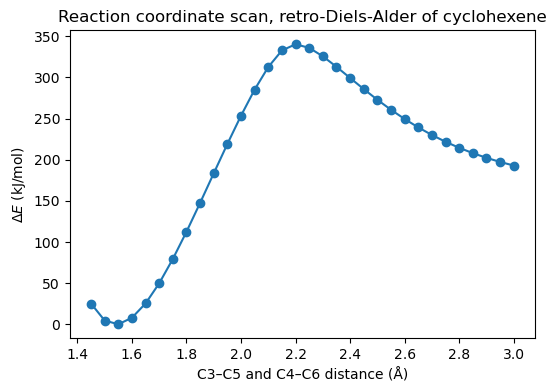

highest point: 2.20 Å, 340.2 kJ/mol above Cs cyclohexene


In [18]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(scan["Length"], scan["DeltaE"], "o-")
ax.set(title="Reaction coordinate scan, retro-Diels-Alder of cyclohexene",
       xlabel=r"C3–C5 and C4–C6 distance (Å)", ylabel=r"$\Delta E$ (kJ/mol)")
plt.show()

top = scan.loc[scan["DeltaE"].idxmax()]
print(f"highest point: {top['Length']:.2f} Å, {top['DeltaE']:.1f} kJ/mol above Cs cyclohexene")

We observe that the **highest energy** occurs near 2.2&nbsp;Å. This is a good structure to use as the **starting point** for a transition state optimization.

## Transition State Optimization

We now have a **starting position** for a transition state optimization.

### The Hessian Calculation

The `RUNTYP` for a transition state optimization is `SADPOINT`. Before we try it, we will check that the 2.2&nbsp;Å structure really sits on the way over a barrier. We can set up the **input file** using *MacMolPlt*. Open the log file for the optimization with bond distances set at 2.2&nbsp;Å (`runs/ch8/Cyclohexene_Cs_SCAN_2.20.log`) and use `Subwindow` &rarr; `Input Builder`. Set the `Run Type` to `Hessian` and set the `MO Guess` to `Huckel` (we could have read the MO data from the `.dat` file for the previous calculation but we are using a low level of theory so we won't bother saving that small amount of time). In `Hess. Options` make sure that the `Vibrational Analysis` button is checked so the file is set to perform a **vibrational analysis** so that we can identify an imaginary vibration (hopefully). Save the input file.

The book comes with the file that *MacMolPlt* wrote, `inputs/ch8/Cyclohexene_TS_Hess.inp`. Its coordinates were taken from my own 2.2&nbsp;Å scan. The cell below puts the coordinates from **your** 2.20&nbsp;Å scan into a copy of it, so that the whole chain of calculations uses your own results.

In [19]:
ts_guess = gt.final_geometry(RUNS / "Cyclohexene_Cs_SCAN_2.20.log", unique=True)
hess_inp = gt.new_input(INPUTS / "Cyclohexene_TS_Hess.inp", RUNS / "Cyclohexene_TS_Hess.inp",
                        atoms=ts_guess)
print(hess_inp.read_text())

!   File created by MacMolPlt 7.7.2
 $CONTRL SCFTYP=RHF RUNTYP=HESSIAN EXETYP=RUN MAXIT=30 MULT=1
    MOLPLT=.TRUE. $END
 $SYSTEM TIMLIM=525600 MEMORY=1000000 PARALL=.TRUE. $END
 $BASIS GBASIS=N31 NGAUSS=6 NDFUNC=1 $END
 $GUESS GUESS=HUCKEL $END
 $SCF DIRSCF=.TRUE. $END
 $FORCE METHOD=ANALYTIC VIBANL=.TRUE. $END
 $DATA 
Cyclohexene
CS

 C        6.0   -1.2569586598   -0.2132650382   -0.6959610279
 C        6.0   -0.3323961115    0.5130799478   -1.4152020493
 C        6.0    1.5815804295   -0.2954373689   -0.6920191202
 H        1.0   -1.8354426219   -0.9644573810   -1.2072922499
 H        1.0    1.4620429881   -1.2209602982   -1.2214203430
 H        1.0   -0.2827418610    0.3958182069   -2.4841211344
 H        1.0    2.1406391786    0.4576867561   -1.2178344191
 H        1.0    0.0049400761    1.4678600886   -1.0628206806
 $END



In [20]:
hess_log = gt.run_gamess(hess_inp, rerun=False)

Cyclohexene_TS_Hess: using existing Cyclohexene_TS_Hess.log (rerun=True to run again)


The input file was submitted to *GAMESS* and was **successful**. *GAMESS* lists the vibrational frequencies in the log file. An imaginary frequency is printed with an `I` after it; `gt.frequencies()` returns it as a negative number. The first six or so values are near zero: they are the translations and rotations of the whole molecule, not real vibrations.

In [21]:
freqs = gt.frequencies(hess_log)
print("lowest frequencies (cm-1):", ", ".join(f"{f:.1f}" for f in freqs[:9]))
print("imaginary frequencies:     ", [f"{-f:.1f} i" for f in freqs if f < -50])

lowest frequencies (cm-1): -910.3, 0.0, 0.0, 0.0, 6.7, 17.3, 19.4, 162.6, 260.9
imaginary frequencies:      ['910.3 i']


There is one large **imaginary frequency** at the top of the list. Now open the log file (`runs/ch8/Cyclohexene_TS_Hess.log`) in *MacMolPlt* and go to `Subwindow` &rarr; `Frequencies`. Clicking on the imaginary frequency reveals the vectors in the display window. Check the display and observe if the vectors align with the reaction coordinate. As we can see in {numref}`fig8_10`, they do. This structure will lead to a **transition state**. We can now perform the saddle point optimization.

```{figure} images/ch8/Diels_10.png
---
width: 450px
name: fig8_10
---
*Structure of the partial optimization with bond lengths of 2.2&nbsp;Å. The imaginary vibration is displayed.*
```

### The Transition State Optimization

Open the log file for the **Hessian calculation**. Click on `Subwindow` &rarr; `Input Builder`. Set the `Run Type` to `Saddle Point`. Set # of `Z-matrix variables` to `42`. We will need to supply a `$ZMAT` group. Set `Stat. Point` &rarr; `Initial Hessian` to `Calculate` (again, we could have cut this out of the `.dat` file and included it in the input file but the time saving is minimal in this case). Save the input file.

To get a `$ZMAT` group we will again set up an energy check **calculation** with the internal coordinates set to auto generate. In *MacMolPlt* this is the `Input Builder` with the `Run Type` set to `Energy` and the `Exe. Type` set to `Check`, and then the line `$ZMAT AUTO=.TRUE. DLC=.TRUE. NONVDW(1)=3,5, 4,6 $END` is added by hand. The `NONVDW` list will be very important here as the bond length is **far past** what is expected for a covalent bond and would not be detected in the automatic internal coordinates otherwise. The cell below makes the same file from the Hessian input.

In [22]:
ts_check_inp = gt.new_input(
    hess_inp, RUNS / "Cyclohexene_TS_ZMAT_Check.inp",
    replacements={"RUNTYP=HESSIAN EXETYP=RUN": "RUNTYP=ENERGY EXETYP=CHECK",
                  "    MOLPLT=.TRUE.": "    NZVAR=42 MOLPLT=.TRUE.",
                  " $FORCE METHOD=ANALYTIC VIBANL=.TRUE. $END\n": ""})
gt.add_group(ts_check_inp, " $ZMAT AUTO=.TRUE. DLC=.TRUE. NONVDW(1)=3,5, 4,6 $END\n")
print(ts_check_inp.read_text())
ts_check_log = gt.run_gamess(ts_check_inp, rerun=False)

!   File created by MacMolPlt 7.7.2
 $CONTRL SCFTYP=RHF RUNTYP=ENERGY EXETYP=CHECK MAXIT=30 MULT=1
    NZVAR=42 MOLPLT=.TRUE. $END
 $SYSTEM TIMLIM=525600 MEMORY=1000000 PARALL=.TRUE. $END
 $BASIS GBASIS=N31 NGAUSS=6 NDFUNC=1 $END
 $GUESS GUESS=HUCKEL $END
 $SCF DIRSCF=.TRUE. $END
 $DATA 
Cyclohexene
CS

 C        6.0   -1.2569586598   -0.2132650382   -0.6959610279
 C        6.0   -0.3323961115    0.5130799478   -1.4152020493
 C        6.0    1.5815804295   -0.2954373689   -0.6920191202
 H        1.0   -1.8354426219   -0.9644573810   -1.2072922499
 H        1.0    1.4620429881   -1.2209602982   -1.2214203430
 H        1.0   -0.2827418610    0.3958182069   -2.4841211344
 H        1.0    2.1406391786    0.4576867561   -1.2178344191
 H        1.0    0.0049400761    1.4678600886   -1.0628206806
 $END
 $ZMAT AUTO=.TRUE. DLC=.TRUE. NONVDW(1)=3,5, 4,6 $END

Cyclohexene_TS_ZMAT_Check: using existing Cyclohexene_TS_ZMAT_Check.log (rerun=True to run again)


The next step is to **find** the `.dat` file, copy the `$ZMAT` group out of it into the saddle point input file, and change `NZVAR` from 42 to the number of entries in the `IZMAT` list. With this **list** of internal coordinates established, *GAMESS* will report their values in the log file and we will be able to directly obtain the bond lengths for the 3,5 and 4,6 bonds in the **transition state** (assuming the calculation succeeds).

The saddle point input written by *MacMolPlt* is `inputs/ch8/Cyclohexene_TS_ZMAT_Saddle.inp`. Note the `$STATPT` group: `HESS=CALC` computes the Hessian at the start, and `HSSEND=.t.` computes it again at the end so that we can check the final structure for its imaginary frequency. The cell below swaps in your coordinates and `NZVAR`, and adds the `$ZMAT` group.

```{note}
The `$ZMAT` group in the `.dat` file holds only the `IZMAT` list. With 89 coordinates for a molecule that needs only 3 &times; 16 &ndash; 6 = 42, *GAMESS* must be told that these are redundant coordinates, which it turns into delocalized internal coordinates. Without `DLC=.TRUE.` the job stops at once with `NUMBER OF INTERNAL COORDINATES IS GREATER THAN (3N-6)`. We also set `AUTO=.FALSE.` so that *GAMESS* uses our list. (We did the same for the scan template above.)
```

In [23]:
ts_zmat = gt.dat_group(RUNS / "Cyclohexene_TS_ZMAT_Check.dat", "$ZMAT")
ts_nzvar = sum(1 for line in ts_zmat.splitlines() if line.strip()[:1].isdigit())
print(f"{ts_nzvar} internal coordinates")

saddle_inp = gt.new_input(INPUTS / "Cyclohexene_TS_ZMAT_Saddle.inp",
                          RUNS / "Cyclohexene_TS_ZMAT_Saddle.inp",
                          atoms=ts_guess, replacements={"NZVAR=89": f"NZVAR={ts_nzvar}"})
gt.add_group(saddle_inp, ts_zmat.replace(" $ZMAT ", " $ZMAT DLC=.TRUE. AUTO=.FALSE.\n       ", 1))
print("\n".join(saddle_inp.read_text().splitlines()[:25]), "\n   ...")

89 internal coordinates
!   File created by MacMolPlt 7.7.2
 $CONTRL SCFTYP=RHF RUNTYP=SADPOINT MAXIT=30 MULT=1 NZVAR=89 MOLPLT=.TRUE. $END
 $SYSTEM TIMLIM=525600 MEMORY=1000000 PARALL=.TRUE. $END
 $BASIS GBASIS=N31 NGAUSS=6 NDFUNC=1 $END
 $GUESS GUESS=HUCKEL $END
 $SCF DIRSCF=.TRUE. $END
 $STATPT OPTTOL=1e-05 NSTEP=200 HESS=CALC HSSEND=.t. $END
 $FORCE METHOD=ANALYTIC VIBANL=.TRUE. $END
 $DATA 
Cyclohexene
CS

 C        6.0   -1.2569586598   -0.2132650382   -0.6959610279
 C        6.0   -0.3323961115    0.5130799478   -1.4152020493
 C        6.0    1.5815804295   -0.2954373689   -0.6920191202
 H        1.0   -1.8354426219   -0.9644573810   -1.2072922499
 H        1.0    1.4620429881   -1.2209602982   -1.2214203430
 H        1.0   -0.2827418610    0.3958182069   -2.4841211344
 H        1.0    2.1406391786    0.4576867561   -1.2178344191
 H        1.0    0.0049400761    1.4678600886   -1.0628206806
 $END
 $ZMAT DLC=.TRUE. AUTO=.FALSE.
         IZMAT(1)=
         1,   1,   2,
         1,

In [24]:
saddle_log = gt.run_gamess(saddle_inp, rerun=False)

Cyclohexene_TS_ZMAT_Saddle: using existing Cyclohexene_TS_ZMAT_Saddle.log (rerun=True to run again)


The calculation was successful and the **saddle point** was located almost immediately. We were almost exactly there already. We **started** with 3,5 and 4,6 bond lengths of 2.200&nbsp;Å; let us see where the saddle point is, and check that the final Hessian (`HSSEND=.t.`) still has exactly one imaginary frequency.

In [25]:
step, ts_energy, gmax, rms = gt.optimization_steps(saddle_log)[-1]
print(f"saddle point found after {step} step(s), E = {ts_energy:.10f} hartree")
for kind, atoms, value in gt.internal_coordinates(saddle_log):
    if kind == "STRETCH" and atoms in [(3, 5), (4, 6)]:
        print(f"  {kind} {atoms}: {value:.7f} Å")

freqs = gt.frequencies(saddle_log)
imaginary = [f for f in freqs if f < -50]
print(f"imaginary frequencies: {[f'{-f:.1f} i' for f in imaginary]}")

barrier = (ts_energy - cs_energy) * HARTREE_TO_KJMOL
print(f"barrier from Cs cyclohexene: {barrier:.1f} kJ/mol")

saddle point found after 1 step(s), E = -232.8796055946 hartree
  STRETCH (3, 5): 2.2019760 Å
  STRETCH (4, 6): 2.2019760 Å
imaginary frequencies: ['902.8 i']
barrier from Cs cyclohexene: 340.3 kJ/mol


## Discussion of the Reaction Coordinate

Let us **examine** the output files for the optimized cyclohexene (`Cyclohexene_Cs_cart.log`), the optimized transition state (`Cyclohexene_TS_ZMAT_Saddle.log`) and the partial optimization at 3.000&nbsp;Å (`Cyclohexene_Cs_SCAN_3.00.log`). Each file numbers its internal coordinates differently, so we **calculate** the same distances and angles from the Cartesian coordinates of the final structure in each file with `gt.distance()` and `gt.angle()`.

In [26]:
structures = {
    "cyclohexene":         gt.final_geometry(cs_log),
    "transition state":    gt.final_geometry(saddle_log),
    "scan at 3.00 Å":      gt.final_geometry(RUNS / "Cyclohexene_Cs_SCAN_3.00.log"),
}
measures = {
    "C3–C5 (breaking bond), Å":   lambda a: gt.distance(a, 3, 5),
    "C5–C6 (becomes ethylene), Å": lambda a: gt.distance(a, 5, 6),
    "C1–C3, Å":                    lambda a: gt.distance(a, 1, 3),
    "C1–C2, Å":                    lambda a: gt.distance(a, 1, 2),
    "angle C1–C3–C5, degrees":     lambda a: gt.angle(a, 1, 3, 5),
}
compare = pd.DataFrame({name: {m: f(atoms) for m, f in measures.items()}
                        for name, atoms in structures.items()})
compare.round(3)

,cyclohexene,transition state,scan at 3.00 Å
"C3–C5 (breaking bond), Å",1.541,2.202,3.000
"C5–C6 (becomes ethylene), Å",1.550,1.383,1.318
"C1–C3, Å",1.509,1.377,1.324
"C1–C2, Å",1.320,1.393,1.474
"angle C1–C3–C5, degrees",111.265,102.584,99.237


We can now **visualize** the starting material, transition state and product. A **diagram** using the bond length coordinates and also the *MacMolPlt* display for each log file is shown in {numref}`fig8_11`.

The 5,6 bond length is a C–C single bond in the cyclohexene with *sp<sup>3</sup>* carbons. Observe how the **bond length** changes from 1.55 to 1.32&nbsp;Å over the course of the **reaction**. The carbon atoms also clearly change from tetrahedral *sp<sup>3</sup>* to planar *sp<sup>2</sup>*. At the same time the C1–C3 bond shortens to a double bond and C1–C2 lengthens to a single bond, as the butadiene forms.

We can see that the ethylene group swings over the top of the butadiene terminal carbons as the reaction proceeds. The 1,3,5 bond angle (the same as the 2,4,6 angle on the other side of the mirror plane) is 111.3&deg; in the cyclohexene and ends up at 99.2&deg; in the product. This is **consistent** with the &pi;-orbital interactions between **frontier molecular orbitals**.

```{figure} images/ch8/Diels_11.png
---
width: 450px
name: fig8_11
---
*The starting material, transition state and product for the retro-Diels-Alder reaction of cyclohexene*
```

So what is the **reaction coordinate**, really? We have used the breaking bond distance as the *x*-axis. We could have used any of the bond **distances** as they all change during the reaction. We could have used the change in **hybridization** from tetrahedral *sp<sup>3</sup>* to planar *sp<sup>2</sup>* for carbon atoms. We could have used bond **angles** that changed. What is the best way to represent the progress of the reaction? You get to decide.

## IRC Calculations

Now that we have an optimized **transition state** structure we can perform an intrinsic reaction coordinate (IRC) calculation. This will follow the imaginary vibration in one direction down to the ground state. We can then **repeat** the IRC in the **other direction**. The benefit of this calculation is that it will **follow the gradient** and is not limited to any specific series of coordinate values. If bond lengths change with different timings as a reaction proceeds then we will follow that groove. This will give us a more accurate picture of the journey from reactant to product (assuming you believe that computational chemistry relates to reality).

The best **reason** to perform the IRC calculation is that it can be used to make a **movie** of the reaction. So let us give it a try.

### Setting Up and Running

In *MacMolPlt* we would take the transition state optimization log file and open it. We would use `Subwindow` &rarr; `Input Builder`, set the `Run Type` to `IRC` and set the `MO Guess` to `MO Read $VEC`. We will also need to manually edit the file.

#### Add the \$IRC Group

*MacMolPlt* will set up an IRC calculation but does not establish some **essential parameters** so you will need to add the `$IRC` group shown below
```text
    $IRC PACE=GS2 OPTTOL=0.0001 MXOPT=300 STRIDE=0.30 
         SADDLE=.TRUE. TSENGY=.TRUE. FORWRD=.TRUE. NPOINT=300 $END
```
The `PACE` algorithm was chosen to be `GS2`. This is the computational **approach** to following the energy gradient down toward ground state. Here we are using the Gonzalez-Schlegel 2nd order method. There are some other choices. When using GS2 we must provide a `$HESS` group.

`OPTTOL` is the tolerance for deciding if the optimization is **finished**. 0.0001 is the default but we could reduce it by a factor of 10 if we want finer accuracy (and have all the time in the world). `MXOPT` is the **maximum** number of optimization steps. Most structures will converge in less than 40 steps. `STRIDE` is the "**distance**" the reaction moves with each step. Its value is generated by the root mean square of all the changes along the reaction coordinate (the imaginary vibration) in the structure. Smaller values will result in less change before the **constrained optimization** is applied. Small values will mean that each step will converge faster and result in a more accurate IRC path. Have you got the time?

The `SADDLE` flag indicates that the starting point is an **optimized** saddle point structure (we could have started with a structure that was already on the way downhill). The `TSENGY` flag requests that the energy of the TS structure be **calculated** (it would be already calculated in the `SADPOINT` job but here we can make sure the value is present in the IRC results as well).

The `NPOINT` variable is how many steps to take **toward** the ground state. This should be a **large number** so that you will reach the ground state along the IRC. The calculation will stop when it reaches a stationary point.

The `FORWRD` flag establishes the **initial direction** over the saddle point. What is "forward" and what is "reverse" is meaningless. Setting it to `.true.` is one direction and `.false.` is the other. We will do **two different jobs** and flip this flag in each.

#### Tracking Internal Coordinates

Because I might want to extract bond lengths and angles from the log file, I asked *GAMESS* to **generate internal coordinates** by including a `$ZMAT` group that flags for redundant internal coordinates. I **declare** the two breaking bonds **explicitly** so that they are not ignored as their lengths reach **beyond** the distance of a covalent bond.

```text
 $ZMAT NONVDW(1)=3,5, 4,6 DLC=.TRUE. AUTO=.TRUE. $END
```

```{note}
Without `NZVAR` in the `$CONTRL` group *GAMESS* ignores this `$ZMAT` group, so the IRC log files contain no internal coordinate tables. That is no loss: *GAMESS* prints the Cartesian coordinates of every point on the path, and *Python* can work out any bond length or angle from them, as we do below.
```

#### Copy in \$HESS and \$VEC Groups

In this input file we are requesting that the MO data be **read in** from the `$VEC` group (`GUESS=MOREAD`, with `NORB` set to the number of occupied orbitals). That data is in the `.dat` file of the saddle point calculation, and so is the `$HESS` group with the final Hessian (thanks to `HSSEND=.t.`). These groups are hundreds of lines long, so we let *Python* copy them. If you would rather not read the orbitals, replace the `$GUESS` group with `$GUESS GUESS=HUCKEL $END`.

```{note}
With the book's `OPTTOL=0.0001`, the run that goes down to cyclohexene came within 0.1&nbsp;kJ/mol of the minimum and then stopped with `NUMERICAL PROBLEMS IN BRACKETING LAMDA`. The boat is a very **shallow** well (remember the plateau mentioned above): the largest gradient was still about 0.001 when the steps became too small to optimize. With `OPTTOL=0.002` *GAMESS* recognises that it has arrived (`STOPPING BECAUSE GRADIENT IS BELOW -OPTTOL-`) and finishes normally, about 1.6&nbsp;kJ/mol above the minimum. We use the same value for both directions.
```

The *MacMolPlt* file that comes with the book, without the `$VEC` and `$HESS` groups, is `inputs/ch8/Diels_Alder_IRC.inp`. The cell below makes the forward and the reverse input files from it, with your transition state coordinates and the two groups copied from your saddle point `.dat` file.

In [27]:
print((INPUTS / "Diels_Alder_IRC.inp").read_text())

saddle_dat = RUNS / "Cyclohexene_TS_ZMAT_Saddle.dat"
vec = gt.dat_group(saddle_dat, "$VEC")
hess = gt.dat_group(saddle_dat, "$HESS")
norb = gt.occupied_orbitals(saddle_log)
ts_atoms = gt.final_geometry(saddle_log, unique=True)

irc_inputs = []
for name, forward in [("Diels_Alder_IRC_F", ".TRUE."), ("Diels_Alder_IRC_R", ".FALSE.")]:
    f = gt.new_input(INPUTS / "Diels_Alder_IRC.inp", RUNS / f"{name}.inp", atoms=ts_atoms,
                     replacements={"NORB=23": f"NORB={norb}", "FORWRD=.TRUE.": f"FORWRD={forward}",
                                   "OPTTOL=0.0001": "OPTTOL=0.002"})
    gt.add_group(f, vec)
    gt.add_group(f, hess)
    irc_inputs.append(f)
    print(f"{f.name}: {len(f.read_text().splitlines())} lines")

!   File created by MacMolPlt 7.7.2
 $CONTRL SCFTYP=RHF RUNTYP=IRC EXETYP=RUN MAXIT=30 MULT=1 MOLPLT=.TRUE. $END
 $SYSTEM TIMLIM=525600 MEMORY=10000000 PARALL=.TRUE. $END
 $IRC PACE=GS2 OPTTOL=0.0001 MXOPT=300 STRIDE=0.30 
      SADDLE=.TRUE. TSENGY=.TRUE. FORWRD=.TRUE. NPOINT=300 $END
 $BASIS GBASIS=N31 NGAUSS=6 NDFUNC=1 $END
 $GUESS GUESS=MOREAD NORB=23 $END
 $SCF DIRSCF=.TRUE. $END
 $DATA 
Cyclohexene
CS

C     6.0    -1.25666    -0.21312    -0.69651
C     6.0    -0.33339     0.51330    -1.41525
C     6.0     1.58235    -0.29584    -0.69140
H     1.0    -1.83470    -0.96482    -1.20757
H     1.0     1.46076    -1.22048    -1.22177
H     1.0    -0.28296     0.39624    -2.48415
H     1.0     2.13857     0.45882    -1.21796
H     1.0     0.00682     1.46650    -1.06163
 $END
 $ZMAT NONVDW(1)=3,5, 4,6 DLC=.TRUE. AUTO=.TRUE. $END



Diels_Alder_IRC_F.inp: 2927 lines
Diels_Alder_IRC_R.inp: 2927 lines


The final input files are thousands of lines long; most of it is the `$VEC` and `$HESS` groups. Here is the top of the forward file, and the first lines of each of the two groups.

In [28]:
text = irc_inputs[0].read_text().splitlines()
print("\n".join(text[:24]))
for group in (" $VEC", " $HESS"):
    i = next(n for n, line in enumerate(text) if line.startswith(group))
    print("\n".join(text[i:i + 3]), "\n   ...")

!   File created by MacMolPlt 7.7.2
 $CONTRL SCFTYP=RHF RUNTYP=IRC EXETYP=RUN MAXIT=30 MULT=1 MOLPLT=.TRUE. $END
 $SYSTEM TIMLIM=525600 MEMORY=10000000 PARALL=.TRUE. $END
 $IRC PACE=GS2 OPTTOL=0.002 MXOPT=300 STRIDE=0.30 
      SADDLE=.TRUE. TSENGY=.TRUE. FORWRD=.TRUE. NPOINT=300 $END
 $BASIS GBASIS=N31 NGAUSS=6 NDFUNC=1 $END
 $GUESS GUESS=MOREAD NORB=23 $END
 $SCF DIRSCF=.TRUE. $END
 $DATA 
Cyclohexene
CS

 C        6.0   -1.2566580222   -0.2131190932   -0.6965109828
 C        6.0   -0.3333830354    0.5133053336   -1.4152537347
 C        6.0    1.5823463452   -0.2958351088   -0.6913954699
 H        1.0   -1.8347024169   -0.9648212731   -1.2075747079
 H        1.0    1.4607571156   -1.2204790314   -1.2217702286
 H        1.0   -0.2829538264    0.3962464475   -2.4841495153
 H        1.0    2.1385694934    0.4588167927   -1.2179603785
 H        1.0    0.0068192606    1.4664988858   -1.0616289019
 $END
 $ZMAT NONVDW(1)=3,5, 4,6 DLC=.TRUE. AUTO=.TRUE. $END
 $VEC   
 1  1 2.54410717E-02 6.1

#### Running Both Directions

We need to perform this calculation **twice**, with the `FORWRD` flag flipped in the second one. Then we can **combine** the two sets of frames to get the whole reaction coordinate. The two jobs do not depend on each other, so the cell below runs them at the same time, one core each. Each IRC point is a small constrained optimization; on my computer the two runs took about three minutes.

In [29]:
from concurrent.futures import ThreadPoolExecutor

with ThreadPoolExecutor(max_workers=2) as pool:
    irc_logs = list(pool.map(lambda f: gt.run_gamess(f, rerun=False), irc_inputs))

Diels_Alder_IRC_R: using existing Diels_Alder_IRC_R.log (rerun=True to run again)Diels_Alder_IRC_F: using existing Diels_Alder_IRC_F.log (rerun=True to run again)



Both files were run by *GAMESS* and the calculations were successful (check the messages above). Each IRC point printed in the log file has its distance along the path (`STOTAL`, in $\sqrt{\text{amu}}\cdot$bohr), its energy and the full geometry. `gt.irc_path()` reads them all. Let us see where each direction ended up.

In [30]:
paths = {}
for log in irc_logs:
    points = gt.irc_path(log)
    s, energy, atoms = points[-1]
    print(f"{log.name}: {len(points)} points, last at s = {s:.2f}, "
          f"E = {energy:.7f} hartree, C3–C5 = {gt.distance(atoms, 3, 5):.3f} Å")
    paths[log.stem] = points

Diels_Alder_IRC_F.log: 17 points, last at s = 5.07, E = -233.0085791 hartree, C3–C5 = 1.541 Å
Diels_Alder_IRC_R.log: 32 points, last at s = 9.59, E = -232.9431416 hartree, C3–C5 = 3.462 Å


One direction goes downhill to cyclohexene (short C3–C5 bonds), the other to butadiene and ethylene (long C3–C5 bonds). Which one is "forward" is just a matter of which way the imaginary vibration happened to point.

### Plotting the IRC

In *MacMolPlt*, `File` &rarr; `Add Frames from File` with `Make these points negative` checked joins the two runs into one path. We do the same thing with *Python*: the points of the run that ends at butadiene and ethylene get negative `s` values, the transition state sits at `s = 0`, and the points of the run that ends at cyclohexene keep positive `s` values. Energies are given in kJ/mol relative to *C<sub>s</sub>* cyclohexene, the same zero as the scan.

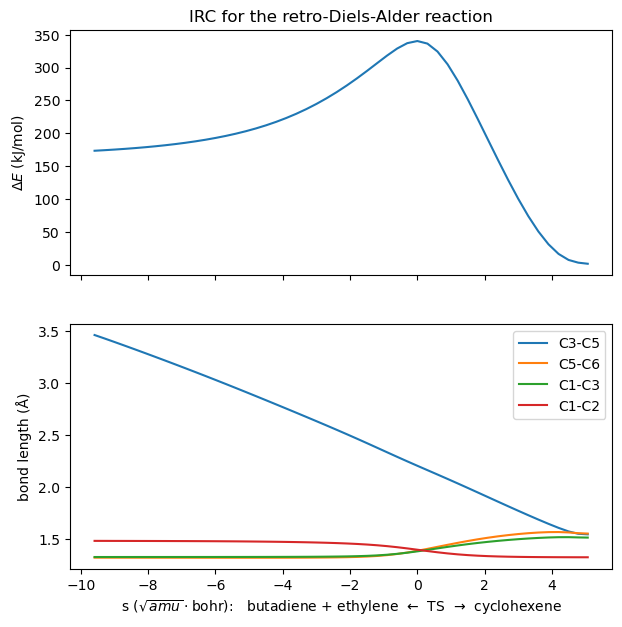

In [31]:
e_ref = cs_energy                                           # Cs cyclohexene energy

rows = [(0.0, ts_energy, gt.final_geometry(saddle_log))]     # the transition state
for points in paths.values():
    to_products = gt.distance(points[-1][2], 3, 5) > 2.2
    sign = -1 if to_products else 1
    rows += [(sign * s, energy, atoms) for s, energy, atoms in points]
rows.sort(key=lambda row: row[0])

irc = pd.DataFrame({
    "s":      [s for s, e, a in rows],
    "DeltaE": [(e - e_ref) * HARTREE_TO_KJMOL for s, e, a in rows],
    "C3-C5":  [gt.distance(a, 3, 5) for s, e, a in rows],
    "C5-C6":  [gt.distance(a, 5, 6) for s, e, a in rows],
    "C1-C3":  [gt.distance(a, 1, 3) for s, e, a in rows],
    "C1-C2":  [gt.distance(a, 1, 2) for s, e, a in rows],
})

fig, (top, bottom) = plt.subplots(2, 1, figsize=(7, 7), sharex=True)
top.plot(irc["s"], irc["DeltaE"], "-")
top.set(ylabel=r"$\Delta E$ (kJ/mol)", title="IRC for the retro-Diels-Alder reaction")
for bond in ["C3-C5", "C5-C6", "C1-C3", "C1-C2"]:
    bottom.plot(irc["s"], irc[bond], label=bond)
bottom.set(xlabel=r"s ($\sqrt{amu}\cdot$bohr):   butadiene + ethylene  ←  TS  →  cyclohexene",
           ylabel="bond length (Å)")
bottom.legend()
plt.show()

The top panel is the energy plot that *MacMolPlt* shows with `File` &rarr; `Energy Plot`. The bottom panel shows the **timing** of the bond changes. Watch C5–C6 (the new ethylene double bond) and C1–C3 and C1–C2 (the butadiene bonds): do they change at the same time as the breaking C3–C5 bond, or earlier, or later?

### The Scan and the IRC Together

Our scan forced the C3–C5 distance to fixed values and optimized everything else. The IRC let the molecule find its own way downhill. If we plot the IRC energies against the C3–C5 distance, we can put both on the same graph.

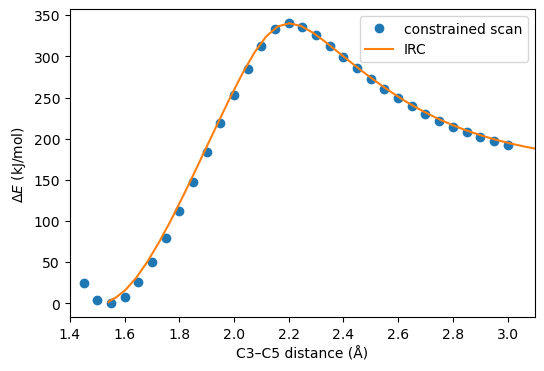

In [32]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(scan["Length"], scan["DeltaE"], "o", label="constrained scan")
ax.plot(irc["C3-C5"], irc["DeltaE"], "-", label="IRC")
ax.set(xlabel="C3–C5 distance (Å)", ylabel=r"$\Delta E$ (kJ/mol)", xlim=[1.4, 3.1])
ax.legend()
plt.show()

Near the transition state the two curves lie on top of each other: our guess that the breaking bond length was a good reaction coordinate was a sensible one. Where they differ, which is lower, and why must it be that one?

### A Note About Editing Input Files

The true power of *GAMESS* can be accessed through the many, many, **many options** available. *MacMolPlt* does not write files that dig deep into the features of *GAMESS*. It sticks to useful and common options. We have **edited** the input file above to access some features that will **improve** the results of our IRC calculation. I learned about these options by digging through the [GAMESS documentation](https://www.msg.chem.iastate.edu/gamess/documentation.html) and reading useful web posts by others who were writing similar educational articles. See [here](https://medium.com/swlh/introduction-to-molecular-modelling-part-5-intrinsic-reaction-coordinate-af7ca328d88d) or [here](http://molecularmodelingbasics.blogspot.com/2009/10/get-reaction-intrinsic-reaction.html) for some examples. Should I have simply left it to them? Am I reinventing the wheel? Yes, but it's my wheel.

### Visualizing the IRC

Open the log file for the first **calculation** (`runs/ch8/Diels_Alder_IRC_F.log`) in *MacMolPlt*. Then use `File` &rarr; `Add Frames from File`. Choose the log file for the reverse calculation (`runs/ch8/Diels_Alder_IRC_R.log`) in the file browser. Check the `Make these points negative` button as this run is in reverse.

Now **drag** the scrubber across the bar at the bottom of the window and **play your movie** back and forth. Choose `File` &rarr; `Energy Plot` to display an energy plot. The current structure will be highlighted on the plot as you **scrub through** all the structures.

```{figure} images/ch8/Diels_IRC.gif
---
width: 450px
name: fig8_12
---
*The Diels-Alder reaction IRC animation*
```

**Watch** how the *sp<sup>3</sup>* carbons convert to *sp<sup>2</sup>* as the bonds break. Also **see** how the ethylene moves to a more vertical angle over the butadiene as the bonds break. **Spin** the structure in the *MacMolPlt* window and **watch** the process from different sides. Can you **see** bond lengths change as &pi;-bonds change to &sigma;-bonds and vice versa?

## A Challenge

### Make It Break the Rules

We know that Diels-Alder reactions proceed with *suprafacial-suprafacial* (*ss*) **stereochemistry**. We can also obey the Woodward-Hoffmann orbital symmetry rules for this reaction with an *antarafacial-antarafacial* (*aa*) process. This process already has a starting point, the half-chair *C<sub>2</sub>* cyclohexene.

Optimize the structure of *C<sub>2</sub>* cyclohexene. Then use it as a **starting point** for a reaction coordinate scan **enforcing** *C<sub>2</sub>* symmetry. Can you optimize the *C<sub>2</sub>* transition state? If so, can an IRC be performed? It would be cool to **compare** the movies for the two reactions. Compare a plot of the potential energies across the reaction coordinate and **comment** on whether the *ss* or the *aa* is faster.

I dare you. No, I double-dog-dare you. Now you **cannot refuse** my challenge.

```{tip}
Every step in this notebook can be reused. Build the *C<sub>2</sub>* molecule in *MacMolPlt*, save the input file in `inputs/ch8/`, and copy the cells above, changing the file names. The scan template, the `for` loop over bond lengths and the `irc_path()` plots all work the same way.
```

### Other Reactions

Can you take the methods **demonstrated** in this chapter and create an IRC for a **conrotatory** and a **disrotatory** electrocyclic reaction? Make the movie. All we really want to do is direct.

Can you create an IRC of a [1,5]-H-shift **sigmatropic rearrangement**? Also try a [3,3] rearrangement. Model the **Claisen** rearrangement and the **Cope** rearrangement. Compare bond lengths in the transition states and apply **Hammond's postulate** when discussing these observations. Make the movies. They might go viral.

## AI Statement

This page was converted from the original Markdown page `8A_Diels_Alder.md` to a *Jupyter* notebook with the help of Claude (Anthropic), following the author's instructions.

- **Original text kept (about 75 %).** The introduction, the *MacMolPlt* building instructions, the discussion of conformers and symmetry, the explanation of `IFZMAT`/`FVALUE`, `NONVDW`, the Hessian and saddle point steps, the discussion of the reaction coordinate, the `$IRC` keyword explanations, the note on editing input files, the visualization instructions and the challenges are the author's words, as are all figures and the five *MacMolPlt* input files in `inputs/ch8/`. Small edits: typos fixed; "*C<sub>2</sub>* cyclohexene, through a *C<sub>2</sub>* transition state" corrected to *C<sub>s</sub>* to match the calculation and {numref}`fig8_7`; `IFFREEZ` corrected to `IFZMAT`; and sentences about copying from `.dat` and `.log` files reworded for *Python*.
- **Written by AI.** The settings cell, all code cells and the paragraphs that introduce them; the check that both breaking bonds are equal; the notes on the 80-column limit and on the ignored `$ZMAT` group in the IRC; the parallel-run tip; the barrier height; the structure comparison table; the IRC energy and bond-length plots and the scan-versus-IRC plot with their questions; the *C<sub>2</sub>* tip; and the helpers `dat_group`, `frequencies` and `irc_path` in `gamess_tools.py`.
- **Changed workflow.** Jobs are run with `run_gamess()` instead of *GamessQ*; the scan files are written with `substitute()` instead of `sed`, and results collected with `optimization_steps()` instead of `grep`; `$ZMAT`, `$VEC` and `$HESS` groups are copied from `.dat` files with `dat_group()` instead of by hand; each step uses the coordinates from your own previous step. The saddle point `$ZMAT` group now includes `DLC=.TRUE. AUTO=.FALSE.`, without which *GAMESS* 2023 R2 stops (89 coordinates is more than 3N–6), the IRC uses the final Hessian of the saddle point run, and the IRC `OPTTOL` was raised from 0.0001 to 0.002 so that the run into the shallow boat well finishes normally. Log excerpts are printed from your own runs instead of pasted in; the scan energies reproduce the original book to all printed digits.
- **GamessQ removed.** At the author's request, the sentences that compared each step with the original book's use of *GamessQ* were shortened to describe only the *Python* step.
- **Comparisons removed.** At the author's request, sentences and shell scripts that compared each step with the previous book's terminal and text-editor workflow were removed or rewritten, so the page reads as written for *Python*.